In [26]:
import tensorflow as tf
import numpy as np  
import pandas as pd  
import matplotlib.pyplot as plt  
import seaborn as sns  

from sklearn.model_selection import train_test_split 
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score 
import torch
import torch.nn as nn
from torchsummary import summary
from torch.utils.data import DataLoader,Dataset
from sklearn.preprocessing import StandardScaler  

from helper import fn_plot_torch_hist

In [27]:
RANDOM_STATE = 24 
np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(seed = RANDOM_STATE) # Set Random Seed for reproducible  results

EPOCHS = 101 # number of epochs
BATCH_SIZE = 32
ALPHA = 0.001 # learning rate
TEST_SIZE = 0.2


params = {'legend.fontsize': 'x-large',
          'figure.figsize': (15, 6),
          'axes.labelsize': 'x-large',
          'axes.titlesize':'x-large',
          'xtick.labelsize':'x-large',
          'ytick.labelsize':'x-large'
         }

plt.rcParams.update(params)

CMAP = plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid')

In [28]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using {torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU'}")


Using CPU


In [4]:
data_df = pd.read_csv(r"C:\Users\PGCP-AI\Downloads\fifa_2019.csv")
data_df.head()

,Unnamed: 0,ID,Name,Age,Photo,Nationality,Flag,Overall,Potential,Club,...,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause
0,0,158023,L. Messi,31,https://cdn.sofifa.org/players/4/19/158023.png,Argentina,https://cdn.sofifa.org/flags/52.png,94,94,FC Barcelona,...,96.0,33.0,28.0,26.0,6.0,11.0,15.0,14.0,8.0,€226.5M
1,1,20801,Cristiano Ronaldo,33,https://cdn.sofifa.org/players/4/19/20801.png,Portugal,https://cdn.sofifa.org/flags/38.png,94,94,Juventus,...,95.0,28.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0,€127.1M
2,2,190871,Neymar Jr,26,https://cdn.sofifa.org/players/4/19/190871.png,Brazil,https://cdn.sofifa.org/flags/54.png,92,93,Paris Saint-Germain,...,94.0,27.0,24.0,33.0,9.0,9.0,15.0,15.0,11.0,€228.1M
3,3,193080,De Gea,27,https://cdn.sofifa.org/players/4/19/193080.png,Spain,https://cdn.sofifa.org/flags/45.png,91,93,Manchester United,...,68.0,15.0,21.0,13.0,90.0,85.0,87.0,88.0,94.0,€138.6M
4,4,192985,K. De Bruyne,27,https://cdn.sofifa.org/players/4/19/192985.png,Belgium,https://cdn.sofifa.org/flags/7.png,91,92,Manchester City,...,88.0,68.0,58.0,51.0,15.0,13.0,5.0,10.0,13.0,€196.4M


In [5]:
# removing rows with position = null
data_df = data_df[data_df["Position"].notnull()]
data_df.head()

,Unnamed: 0,ID,Name,Age,Photo,Nationality,Flag,Overall,Potential,Club,...,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause
0,0,158023,L. Messi,31,https://cdn.sofifa.org/players/4/19/158023.png,Argentina,https://cdn.sofifa.org/flags/52.png,94,94,FC Barcelona,...,96.0,33.0,28.0,26.0,6.0,11.0,15.0,14.0,8.0,€226.5M
1,1,20801,Cristiano Ronaldo,33,https://cdn.sofifa.org/players/4/19/20801.png,Portugal,https://cdn.sofifa.org/flags/38.png,94,94,Juventus,...,95.0,28.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0,€127.1M
2,2,190871,Neymar Jr,26,https://cdn.sofifa.org/players/4/19/190871.png,Brazil,https://cdn.sofifa.org/flags/54.png,92,93,Paris Saint-Germain,...,94.0,27.0,24.0,33.0,9.0,9.0,15.0,15.0,11.0,€228.1M
3,3,193080,De Gea,27,https://cdn.sofifa.org/players/4/19/193080.png,Spain,https://cdn.sofifa.org/flags/45.png,91,93,Manchester United,...,68.0,15.0,21.0,13.0,90.0,85.0,87.0,88.0,94.0,€138.6M
4,4,192985,K. De Bruyne,27,https://cdn.sofifa.org/players/4/19/192985.png,Belgium,https://cdn.sofifa.org/flags/7.png,91,92,Manchester City,...,88.0,68.0,58.0,51.0,15.0,13.0,5.0,10.0,13.0,€196.4M


In [6]:
data_df.shape

(18147, 89)

In [7]:
# Following columns appear to be relevant for our analysis
rel_cols = ['Position', 'Finishing', 'HeadingAccuracy', 'ShortPassing', 'Volleys', 'Dribbling',
            'Curve', 'FKAccuracy', 'LongPassing', 'BallControl', 'Acceleration',
            'SprintSpeed', 'Agility', 'Reactions', 'Balance', 'ShotPower',
            'Jumping', 'Stamina', 'Strength', 'LongShots', 'Aggression',
            'Interceptions', 'Positioning', 'Vision', 'Penalties', 'Composure',
            'Marking', 'StandingTackle', 'SlidingTackle', 'GKDiving', 'GKHandling',
            'GKKicking', 'GKPositioning', 'GKReflexes']
goalkeeper = 'GK'
forward = ['ST', 'LW', 'RW', 'LF', 'RF', 'RS','LS', 'CF']
midfielder = ['CM','RCM','LCM', 'CDM','RDM','LDM', 'CAM', 'LAM', 'RAM', 'RM', 'LM']
defender = ['CB', 'RCB', 'LCB', 'LWB', 'RWB', 'LB', 'RB']

data_df = data_df[rel_cols]
data_df.head()

,Position,Finishing,HeadingAccuracy,ShortPassing,Volleys,Dribbling,Curve,FKAccuracy,LongPassing,BallControl,...,Penalties,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes
0,RF,95.0,70.0,90.0,86.0,97.0,93.0,94.0,87.0,96.0,...,75.0,96.0,33.0,28.0,26.0,6.0,11.0,15.0,14.0,8.0
1,ST,94.0,89.0,81.0,87.0,88.0,81.0,76.0,77.0,94.0,...,85.0,95.0,28.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0
2,LW,87.0,62.0,84.0,84.0,96.0,88.0,87.0,78.0,95.0,...,81.0,94.0,27.0,24.0,33.0,9.0,9.0,15.0,15.0,11.0
3,GK,13.0,21.0,50.0,13.0,18.0,21.0,19.0,51.0,42.0,...,40.0,68.0,15.0,21.0,13.0,90.0,85.0,87.0,88.0,94.0
4,RCM,82.0,55.0,92.0,82.0,86.0,85.0,83.0,91.0,91.0,...,79.0,88.0,68.0,58.0,51.0,15.0,13.0,5.0,10.0,13.0


In [8]:
#Assign labels to goalkeepers
data_df['Position_encoded'] = 0

data_df.loc[data_df["Position"] == "GK", "Position_encoded"] = 0

#Defenders
data_df.loc[data_df["Position"].isin(defender), "Position_encoded"] = 1

#Midfielders
data_df.loc[data_df["Position"].isin(midfielder), "Position_encoded"] = 2

#Forward
data_df.loc[data_df["Position"].isin(forward), "Position_encoded"] = 3

# Convert Column "Position" to numeric so that Pandas does not complain
data_df['Position_encoded'] = pd.to_numeric(data_df['Position_encoded'], 
                                            downcast="integer")

labels = data_df['Position_encoded']
features = data_df.drop(['Position', 'Position_encoded'], axis = 1)

# labels = {0: 'Goal Keeper', 1: 'Defender', 2: 'Mid-Fielder', 3: 'Forward'}
features.shape, labels.shape

((18147, 33), (18147,))

In [9]:
# splitting in train ans test datasets
X_train, X_test, y_train, y_test = train_test_split(features,labels,
                                     stratify=labels,
                                     test_size=TEST_SIZE, 
                                     random_state=RANDOM_STATE )
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((14517, 33), (3630, 33), (14517,), (3630,))

In [10]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Define Datasets

In [11]:
class FifaDataset(Dataset):
    def __init__(self, X,y):
        self.X = torch.tensor(X, dtype = torch.float32)
        self.y = torch.tensor(y, dtype = torch.long) 

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [12]:
train_dataset = FifaDataset(X_train, y_train)
train_loader = DataLoader(dataset = train_dataset, batch_size = BATCH_SIZE, shuffle = True)

In [13]:
test_dataset = FifaDataset(X_test, y_test.to_numpy())
test_loader = DataLoader(dataset = test_dataset, batch_size = BATCH_SIZE, shuffle = True)

In [14]:
for b_idx, (data, target) in enumerate(train_loader):
    print(f'Batch {b_idx} : \nData :- {data.shape} \nLabels :- {target.shape}')

Batch 0 : 
Data :- torch.Size([32, 33]) 
Labels :- torch.Size([32])
Batch 1 : 
Data :- torch.Size([32, 33]) 
Labels :- torch.Size([32])
Batch 2 : 
Data :- torch.Size([32, 33]) 
Labels :- torch.Size([32])
Batch 3 : 
Data :- torch.Size([32, 33]) 
Labels :- torch.Size([32])
Batch 4 : 
Data :- torch.Size([32, 33]) 
Labels :- torch.Size([32])
Batch 5 : 
Data :- torch.Size([32, 33]) 
Labels :- torch.Size([32])
Batch 6 : 
Data :- torch.Size([32, 33]) 
Labels :- torch.Size([32])
Batch 7 : 
Data :- torch.Size([32, 33]) 
Labels :- torch.Size([32])
Batch 8 : 
Data :- torch.Size([32, 33]) 
Labels :- torch.Size([32])
Batch 9 : 
Data :- torch.Size([32, 33]) 
Labels :- torch.Size([32])
Batch 10 : 
Data :- torch.Size([32, 33]) 
Labels :- torch.Size([32])
Batch 11 : 
Data :- torch.Size([32, 33]) 
Labels :- torch.Size([32])
Batch 12 : 
Data :- torch.Size([32, 33]) 
Labels :- torch.Size([32])
Batch 13 : 
Data :- torch.Size([32, 33]) 
Labels :- torch.Size([32])
Batch 14 : 
Data :- torch.Size([32, 33]) 
La

### Model Using Module

In [15]:
class Model(nn.Module):
    def __init__(self, input_dim):
        super(Model, self).__init__()
        self.layer1 = nn.Linear(input_dim, 18)
        self.activ1 = nn.SiLU()
        self.layer2 = nn.Linear(18,4)

    def forward(self, x):
        x = self.layer1(x)
        x = self.activ1(x)
        x = self.layer2(x)
        return x

In [16]:
model = Model(input_dim = X_train.shape[1]).to(device = device)

In [17]:
loss_fn = nn.CrossEntropyLoss()  # Loss Function
optimizer = torch.optim.Adam(model.parameters(), # Parameters to potimized
                             lr = ALPHA )# Learning Rate
loss, tloss, acc, tacc , n_epoch = [], [], [], [], []

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0
    epoch_acc = 0
    tepoch_loss = 0
    tepoch_acc = 0

    for batch_idx, (train_X, train_y) in enumerate(train_loader):
        train_x = train_X.to(device)
        train_y = train_y.to(device)

        predict_prob = model(train_x)
        batch_loss = loss_fn(predict_prob, train_y)

        epoch_loss += (batch_loss.item() - epoch_loss)/(batch_idx + 1)

        # Back Propagation
        optimizer.zero_grad()  # reset
        batch_loss.backward()  # back Propagation (dws, dbs)
        optimizer.step() # w = w + alpha * dw
        _, y_pred = torch.max(predict_prob, dim = 1)
        batch_acc = accuracy_score(train_y.cpu().numpy(), y_pred.data.cpu())

        epoch_acc += (batch_acc - epoch_acc)/(batch_idx + 1)
        
    loss.append(epoch_loss)
    acc.append(epoch_acc)

    model.eval()
    with torch.inference_mode():
        for batch_idx, (test_X, test_y) in enumerate(test_loader):
            test_X = test_X.to(device)
            test_y = test_y.to(device)
    
            predict_prob = model(test_X)
            batch_loss = loss_fn(predict_prob, test_y)
    
            tepoch_loss += (batch_loss.item()  - tepoch_loss)/(batch_idx + 1)
    
            _, y_pred = torch.max(predict_prob, 1)
            batch_acc = accuracy_score(test_y.cpu().numpy(), y_pred.data.cpu())
    
            tepoch_acc += (batch_acc - tepoch_acc)/(batch_idx + 1)
                    
        tloss.append(tepoch_loss)
        tacc.append(tepoch_acc)    
        n_epoch.append(epoch)
    if epoch % 10 == 0:
        print(f'At Epoch : {epoch:4d} : Train Loss - {epoch_loss:.4f} |'
              f'Test Loss - {tepoch_loss:.4f} |'
              f'Train Accuracy - {epoch_acc:.4f} |'
              f'Test Accuracy - {tepoch_acc:.4f}'
        )

At Epoch :    0 : Train Loss - 0.5580 |Test Loss - 0.3759 |Train Accuracy - 0.7866 |Test Accuracy - 0.8389
At Epoch :   10 : Train Loss - 0.2844 |Test Loss - 0.2966 |Train Accuracy - 0.8839 |Test Accuracy - 0.8720
At Epoch :   20 : Train Loss - 0.2761 |Test Loss - 0.2952 |Train Accuracy - 0.8863 |Test Accuracy - 0.8746
At Epoch :   30 : Train Loss - 0.2711 |Test Loss - 0.2929 |Train Accuracy - 0.8874 |Test Accuracy - 0.8741
At Epoch :   40 : Train Loss - 0.2665 |Test Loss - 0.2960 |Train Accuracy - 0.8900 |Test Accuracy - 0.8752
At Epoch :   50 : Train Loss - 0.2643 |Test Loss - 0.3007 |Train Accuracy - 0.8905 |Test Accuracy - 0.8748
At Epoch :   60 : Train Loss - 0.2620 |Test Loss - 0.2998 |Train Accuracy - 0.8906 |Test Accuracy - 0.8757
At Epoch :   70 : Train Loss - 0.2608 |Test Loss - 0.3012 |Train Accuracy - 0.8906 |Test Accuracy - 0.8755
At Epoch :   80 : Train Loss - 0.2591 |Test Loss - 0.3050 |Train Accuracy - 0.8924 |Test Accuracy - 0.8757
At Epoch :   90 : Train Loss - 0.2576

In [20]:
loss_df = pd.DataFrame({
    'Epoch':n_epoch,
    'Train Loss':loss,
    'Test Loss':tloss,
    'Train Accuracy':acc,
    'Test Accuracy':tacc
})
loss_df

,Epoch,Train Loss,Test Loss,Train Accuracy,Test Accuracy
0,0,0.557955,0.375914,0.786648,0.838933
1,1,0.335815,0.327976,0.861643,0.857025
2,2,0.311884,0.313434,0.869903,0.865171
3,3,0.302745,0.306620,0.875957,0.867246
4,4,0.297154,0.303752,0.878094,0.865876
...,...,...,...,...,...
96,96,0.256795,0.305283,0.893132,0.875940
97,97,0.257102,0.307333,0.892651,0.872220
98,98,0.256598,0.307015,0.893854,0.870849
99,99,0.256542,0.309502,0.893031,0.871006


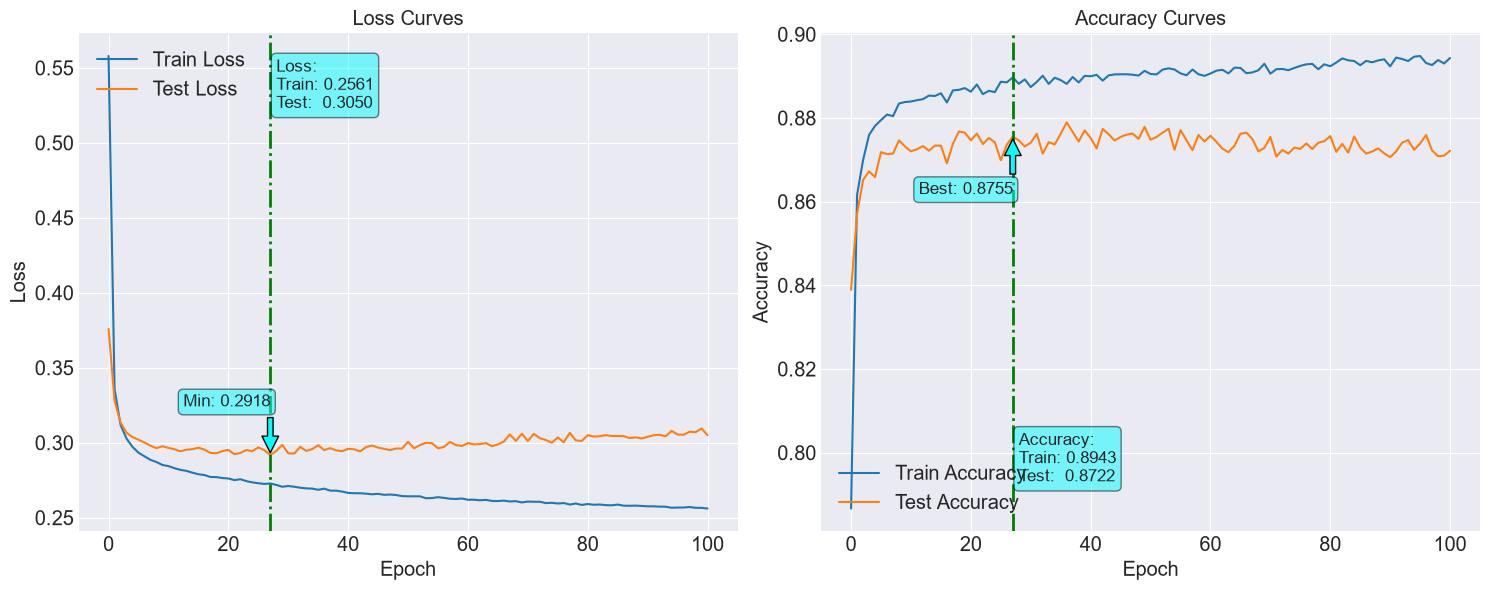

In [29]:
fn_plot_torch_hist(loss_df)